In [1]:
%matplotlib qt
import numpy as np
import matplotlib.pyplot as plt
import roboticstoolbox as rtb
from spatialmath import SE3
from workspace import *

In [2]:
L1 = 5
L2 = 3
L3 = 2

e1 = rtb.RevoluteMDH(a=0,alpha=0,d=L1,
                     qlim=[-np.radians(160),np.radians(185)])

e2 = rtb.RevoluteMDH(a=0,alpha=np.radians(90),d=0,
                     qlim=[-np.radians(60),np.radians(140)])

e3 = rtb.RevoluteMDH(a=L2,alpha=0,d=0,
                     qlim=[-np.radians(120),np.radians(155)])

robot = rtb.DHRobot([e1,e2,e3],name='Antropomorfico')

robot.tool = SE3.Tx(L3)

print(robot)

DHRobot: Antropomorfico, 3 joints (RRR), dynamics, modified DH parameters
┌──────┬───────┬─────┬────┬─────────┬────────┐
│ aⱼ₋₁ │ ⍺ⱼ₋₁  │ θⱼ  │ dⱼ │   q⁻    │   q⁺   │
├──────┼───────┼─────┼────┼─────────┼────────┤
│    0 │  0.0° │  q1 │  5 │ -160.0° │ 185.0° │
│    0 │ 90.0° │  q2 │  0 │  -60.0° │ 140.0° │
│    3 │  0.0° │  q3 │  0 │ -120.0° │ 155.0° │
└──────┴───────┴─────┴────┴─────────┴────────┘

┌──────┬───────────────────────────────────┐
│ tool │ t = 2, 0, 0; rpy/xyz = 0°, 0°, 0° │
└──────┴───────────────────────────────────┘



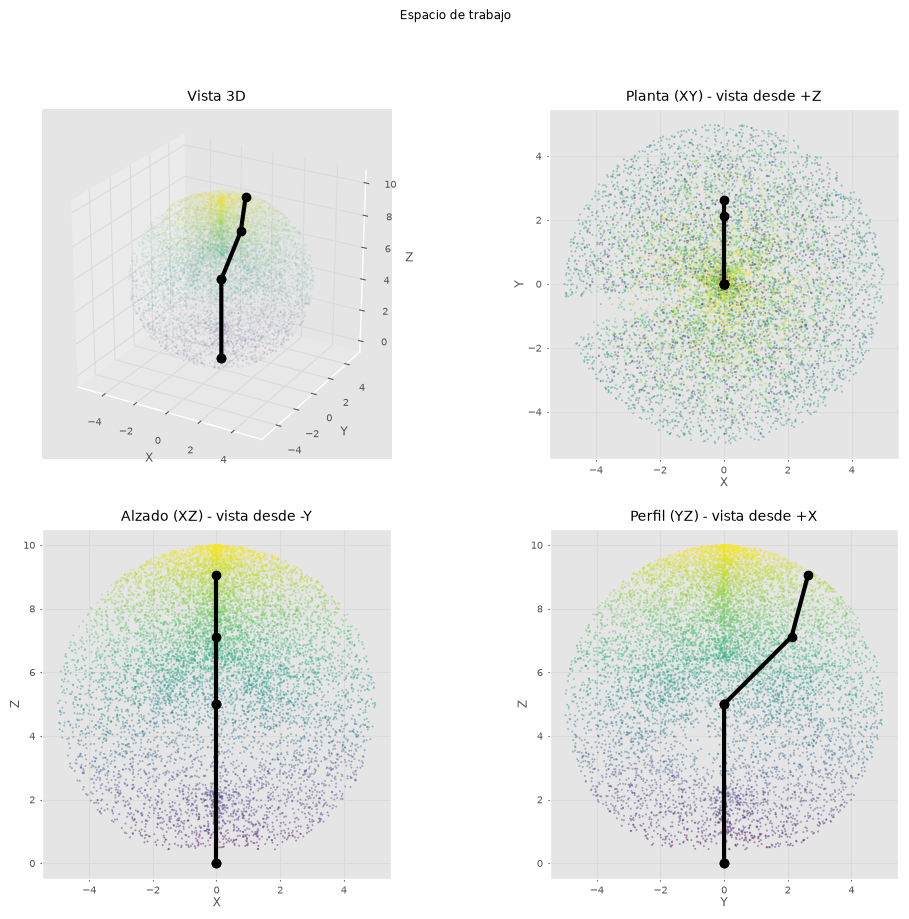

In [3]:
Q,P = espacio_trabajo(robot=robot,N=10000,devolver_q=True)

q = np.deg2rad([90,45,30])

mostrar(P,vista='Todas',robot=robot,q=q)

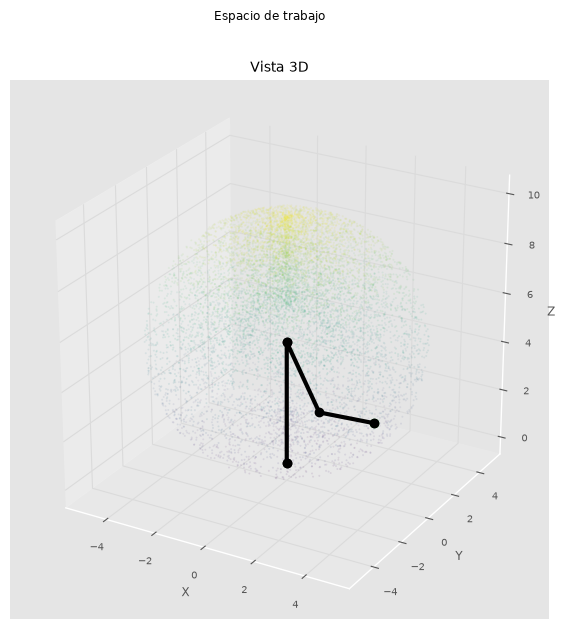

In [4]:
Obj = SE3.Trans(3,1,2)

sol = robot.ikine_LM(Obj,mask=[1,1,1,0,0,0])

mostrar(P,vista='3d',robot=robot,q=sol.q if sol.success else None,puntos=Obj.t,
        colores_puntos='g' if sol.success else 'r')

In [11]:
pasos=15
P = espacio_trabajo(robot, N=10000)

triangulo = [(-3,-2.0,2),(-2,-2.0,4),(-1,-2.0,2)]

puntos, idx = poligono(triangulo,pasos=pasos)

n = len(puntos)
qs = np.full((n,robot.n),np.nan)
q_prev = None

for k,p in enumerate(puntos):
    sol = robot.ikine_LM(SE3(*p),mask=[1,1,1,0,0,0],
                         q0=q_prev,joint_limits=True)
    if sol.success:
        qs[k] = q_prev = sol.q

qs, valido, colores = validar_ik(robot,qs,puntos)

mostrar(P,vista='todas',puntos=puntos,colores_puntos=colores)
qj,Pj = comparar_jtraj(robot, puntos,qs,valido,idx,P=P)

#Comparativa para validacion de cierre de la trayectoria
print("¿Cierre la figura (q inicial = q final)?",
      np.allclose(qs[0],qs[-1]))

43 de 43 puntos correctos
Desviación máxima de jtraj: 1.016
¿Cierre la figura (q inicial = q final)? True


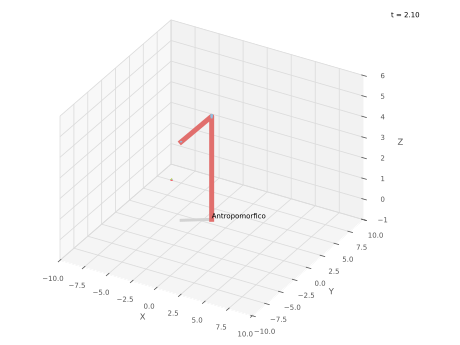

PyPlot3D backend, t = 2.1500000000000004, scene:
  robot: Text(0.0, 0.0, 'Antropomorfico')

In [8]:
robot.plot(qs,backend='pyplot',dt=0.05,
           limits=[-10,10,-10,10,-1,6])

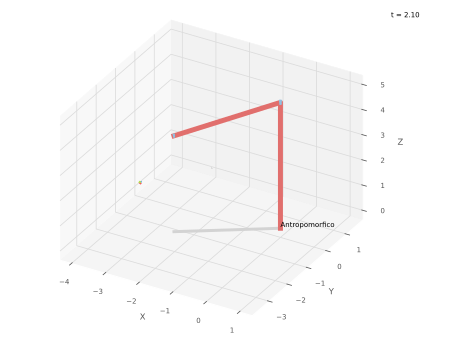

PyPlot3D backend, t = 2.1500000000000004, scene:
  robot: Text(0.0, 0.0, 'Antropomorfico')

In [9]:
robot.plot(qj,backend='pyplot')